In [1]:
import sys
import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import os 
import random
import matplotlib.pyplot as plt

sys.path.append('../')

from evaluate import evaluate
import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier

In [2]:
#Wider jupyterlab
#from IPython.display import display, HTML
#display(HTML("<style>.container { width:70% !important; }</style>"))

In [3]:
inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [4]:
classes = [ i for i in LABEL_MAPPING.keys()]

## Load models and their configs and dataloaders

In [5]:


models = {
    'faostat-static' : {
        'wandb_id' : 'mvnz51pc', 
    },     

    'faostat-dynamic' : {
        'wandb_id' : 'nq0z1lof', 
    }, 
    
    #'loc' : {
    #    'wandb_id' : '7nv1stm4', 
    #},     
    
    
    'deduce-static' : {
        'wandb_id' : '3ktqu3rn', 
    }, 
    
    'deduce-dynamic' : {
        'wandb_id' : '1cn9ftp1', 
    },
    #'goldman' : {
    #    'wandb_id' : 'jezpdfdf', 
    #}, 
    
    'img' : {
        'wandb_id' : 'ey2o6bq6',
    },
    
    'img+deduce-dynamic' : {
        'wandb_id' : '9bmoakj7',
    },
    
}

In [6]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
n_classes = 12
num_images = 4


In [7]:
#Load config & dataloader for each model
for key, value in models.items():
    _id = value['wandb_id']
    model_dir = os.path.join('../models_trained', _id)
    config_path = os.path.join(model_dir, 'config.json')
    with open(config_path) as source:
        config = json.loads(source.read())
        
    
    #This is just to update the paths because the paths specified in the configs at the time these models
    #were trained are not correct (i've moved the tabular data)
    config['data'] = {
        "annotation_file": "/home/jan/Documents/EPFL/project_2/data/labels/dataset_v4/labels_55k.csv",
        "image_folder": "/home/jan/Documents/EPFL/project_2/data/images/dataset_v4/55k/SR_four_images",
        "forestloss_folder": "/home/jan/Documents/EPFL/project_2/data/forestloss_tiles/dataset_v4",
        "faostat_data": "/home/jan/Documents/EPFL/project_2/data/tabular/faostat_2000_2020_dynamic.csv",
        "deduce_data": "/home/jan/Documents/EPFL/project_2/data/tabular/deduce_yearly.csv",
        "goldman_data": "/home/jan/Documents/EPFL/project_2/data/tabular/goldman.csv",
        "output_folder":  "models_trained/"
    }

        

    models[key]['config'] = config
    
    # fetch dataloaders
    dataloaders = dataloader.fetch_dataloader(
        ['val'], config)
    models[key]['val_dl'] = dataloaders['val']
    

    model = MultiModalDriverClassifier(n_classes,  **config)
    model = model.to(device)
    
    trained_model_path = f'../models_trained/{_id}/best.pt'

    _ = model.load_state_dict(torch.load(trained_model_path)['state_dict'])
    _ = model.eval()
    
    models[key]['model'] = model
    


In [8]:
#This should be the same
for key in models:
    print(models[key]['val_dl'].dataset.img_labels.shape)

(9977, 7)
(9977, 7)
(9977, 7)
(9977, 7)
(9977, 7)
(9977, 7)


In [9]:
df = models['faostat-static']['val_dl'].dataset.img_labels

df.sample(1).sampleid.values[0]

20047308

## Plot images with predictions 

In [10]:
def plot_image_with_tmf(data, tmf, label):
   
    fig, ax = plt.subplots(1,2, figsize=(10,8))
    img = data[:3, :, :].detach()
    img = img/0.25
    print(label)
    
    ax[0].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
    
    ax[0].set_xticks([])
    ax[0].set_yticks([])
    ax[1].imshow(tmf.numpy()  )

    fig.tight_layout()
    plt.show()


def plot_ts_with_tmf(data, tmf, label):
    
    n_images = data.shape[0]
    print("Ground truth: ", label)
    fig, ax = plt.subplots(1,n_images+1, figsize=(16, 10))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])

    ax[n_images].imshow(tmf.numpy()  )

    fig.tight_layout()
    plt.show()
    
    
    

def plot_predictions(models_dict, classes):

    _x = np.arange(len(classes))  # the label locations
    fig, ax = plt.subplots(1,figsize=(16,10))
    
    num_models = len(models_dict)
    
    col_width = 0.8/num_models  # the total width is 1, using 0.9 to create some space between classes, divided by the n of models

    
    for i, model_name in enumerate(models_dict.keys()):
        
        offset = -0.35 + i*col_width #Starting at -0.45, each column should be next to previous one
        ax.bar(
            _x+offset, 
            models_dict[model_name]['probabilities'].squeeze(), 
            width=col_width, 
            #color='r',  
            align='center', 
            label=model_name)

    
    plt.xticks(_x, classes) 
    plt.tight_layout()
    plt.legend(bbox_to_anchor=(0.2, 1.05), ncol=5)
    plt.show()

In [11]:
np.set_printoptions(suppress=True) #suppress scientific notation for numpy


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


geometry         POINT (-52.674328689533716 -13.339846355303724)
driver                                                       soy
sampleid                                                10593446
dataset                                            mapbiomas.csv
split                                                        val
country                                                   Brazil
goldman_index                                            [14662]
Name: 9162, dtype: object
faostat-static
faostat-dynamic
deduce-static
deduce-dynamic
img
img+deduce-dynamic
Ground truth:  soy


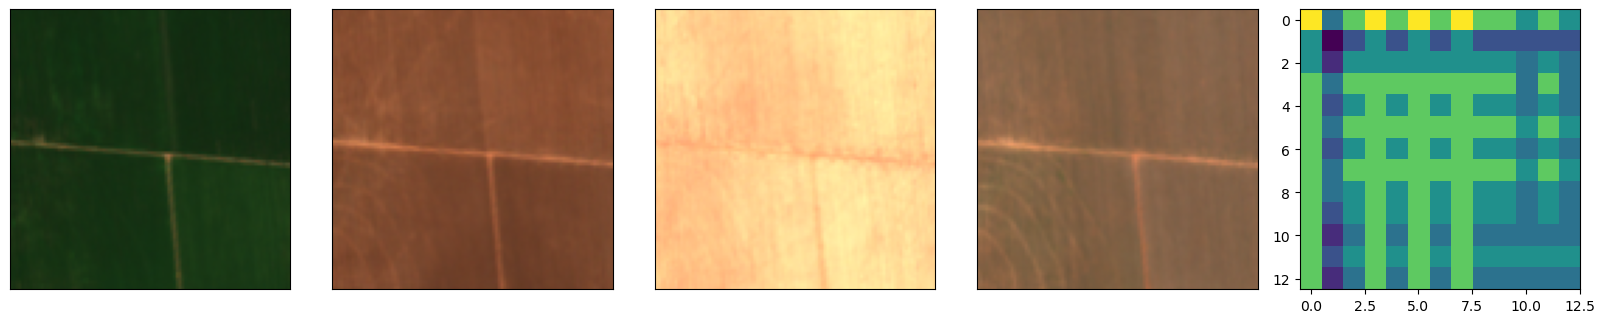

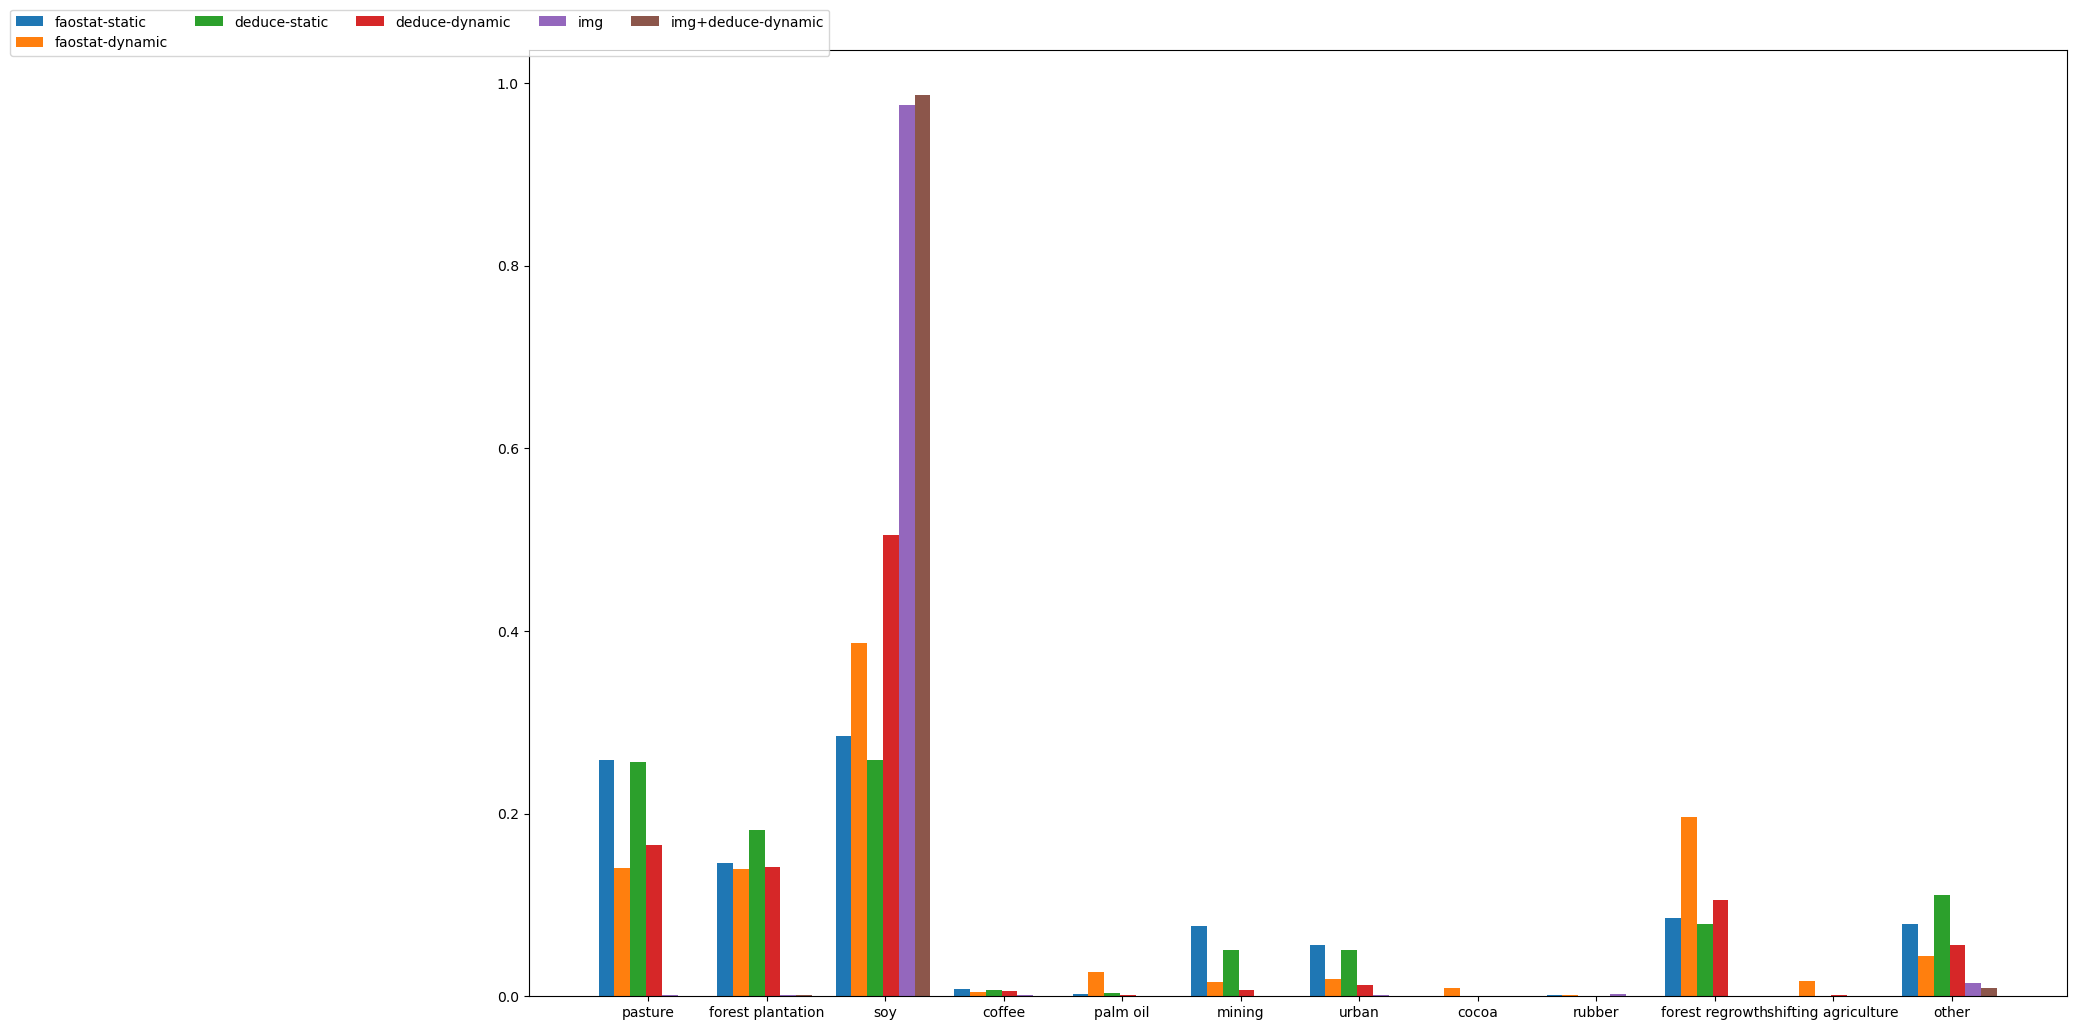

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,other
faostat-static,0.268911,-0.345226,1.888837,-0.029658,0.009616,-0.345226,-0.345226,-0.009427,0.005581,-0.345226,-0.345226,-0.345226
faostat-dynamic,0.000000,-0.132012,0.000000,0.000000,0.000000,-0.132012,-0.132012,0.000000,0.000000,-0.132012,-0.132012,-0.132012
deduce-static,74.335419,1.255654,8.111852,0.248062,0.032633,-0.649451,-0.649451,0.043120,0.039801,-0.649451,-0.649451,-0.649451
deduce-dynamic,4.798213,0.013801,0.901329,0.011674,0.000795,-1.323437,-1.323437,0.001931,0.002754,-1.323437,-1.323437,-1.323437


2003.0 2003.0


In [ ]:

while True:
    idx = df.sample(1).index.values[0]
    sampleid = df.iloc[idx].sampleid
    print(df.iloc[idx])
    
    for model_name in models.keys():
        _inputs, label = models[model_name]['val_dl'].dataset.__getitem__(idx)

        img, loc, tabular, forestloss = _inputs[0].unsqueeze(0).to(device), _inputs[1].unsqueeze(0).to(device), _inputs[2].unsqueeze(0).to(device), _inputs[3].unsqueeze(0).to(device)
        models[model_name]['inputs'] = img, loc, tabular, forestloss
        if model_name == 'img':
            images = img #Just to have an actual image and not an empty placeholder for plotting
        y_hat = models[model_name]['model'](img, loc, tabular, forestloss)


        models[model_name]['probabilities'] = F.softmax(y_hat, dim=1).detach().cpu().numpy()

    tab_vals = []
    for model_name in ['faostat-static', 'faostat-dynamic', 'deduce-static', 'deduce-dynamic']:
        tab_vals.append(models[model_name]['inputs'][2].detach().cpu().squeeze().numpy())
        
    tabular_vals = pd.DataFrame(tab_vals, columns=[classes])
    tabular_vals.index = ['faostat-static', 'faostat-dynamic', 'deduce-static', 'deduce-dynamic']
    
    with rasterio.open(f'../data/forestloss_tiles/dataset_v4/{sampleid}.tif') as src:
        forestloss_patch = src.read()
    
    years = forestloss_patch[(forestloss_patch >= 2000) & (forestloss_patch <= 2020)]
    min_year, max_year = years.min(), years.max()
        
    
    plot_ts_with_tmf(images.detach().cpu().squeeze(), forestloss.detach().cpu().squeeze(),  label= inverse_label_mapping[label])
    plot_predictions(models, classes)
    display(tabular_vals)
    print(min_year, max_year)

    _waitforinput = input()

    clear_output(wait=True)

In [103]:
dynamic_df = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/tabular/faostat_2000_2020_dynamic.csv")


In [110]:
country_data = dynamic_df.loc[dynamic_df['country'] == 'Bolivia (Plurinational State of)']

In [112]:
tabular_column_names = ['Cattle', 'Soya beans', 'Cocoa beans', 'Coffee, green', 'Oil palm fruit', 'Natural rubber in primary forms']


In [114]:
_class = tabular_column_names[0]

In [115]:
production_at_the_start = country_data.loc[(country_data.Item == _class) & (country_data.Year == int(min_year)), 'Value' ].item()

In [116]:
production_at_the_start

0.2917127640677132

In [117]:
production_at_the_end = country_data.loc[(country_data.Item == _class) & (country_data.Year == int(max_year)), 'Value' ].item()


In [119]:
rate = production_at_the_end - production_at_the_start

In [120]:
rate

0.10750477557874222

In [124]:
def _get_dynamic_commodity_data(tab_data, country, forestloss_patch, tab_col_names): #TODO: Max year should be 2022, this is temporary

    years = forestloss_patch[(forestloss_patch >= 2000) & (forestloss_patch <= 2020)]
    try:
        min_year, max_year = years.min(), years.max()
        #TODO: consider using not the absolute min,max, but percentiles
        #min_year, max_year = np.percentile(years.flatten(), 10), np.percentile(years.flatten(), 90)
    except:
        min_year, max_year = 2000, 2020


    country_data = tab_data.loc[tab_data['country'] == country]

    rates = []
    for _class in tab_col_names:
        try:
            production_at_the_start = country_data.loc[(country_data.Item == _class) & (country_data.Year == int(min_year)), 'Value' ].item()
            production_at_the_end = country_data.loc[(country_data.Item == _class) & (country_data.Year == int(max_year)), 'Value' ].item()
            rate = production_at_the_end - production_at_the_start
        except ValueError: #Signifies that one (or both) of the values are missing
            rate = np.nan

        rates.append(rate)

    return np.array(rates)

In [126]:
rates = _get_dynamic_commodity_data(dynamic_df, 'Bolivia (Plurinational State of)', forestloss_patch, tabular_column_names)

In [128]:
tabular_cls_indices = torch.tensor([0, 2, 7, 3, 4, 8]) 

rates = np.nan_to_num(rates.astype('float32'), nan=0.0)
tabular_data = torch.zeros((12), dtype=torch.float)
tabular_data[tabular_cls_indices] = torch.Tensor(rates.squeeze())
tabular_data = torch.nan_to_num(tabular_data, nan=0.0)
tabular_data = tabular_data.squeeze()

In [129]:
tabular_data

tensor([ 0.1075,  0.0000,  0.4398, -0.0010,  0.0000,  0.0000,  0.0000,  0.0028,
        -0.0016,  0.0000,  0.0000,  0.0000])